<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Kalshi Prediction Markets](https://github.com/Query-farm/vgi-kalshi)

Live and archived Kalshi prediction markets, with order books, prices, trades and settlements.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-kalshi/blob/main/notebooks/02_discover_contracts_with_source_context.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-kalshi/blob/main/notebooks/README.md)

## A busy contract still needs context

Which contracts in a discovered series pass explicit lifecycle, declared-source and activity checks? We preserve every rejected row so a shortlist cannot hide its denominator.

**Synthetic data, real SQL worker.** Every `DEMOWX` contract, event, price, quantity, timestamp and source URL in this example is fictional. A strict loopback HTTP server supplies the declared responses to the published worker; there is no live fallback and no authentication. The helper creates an empty temporary SQL secret directory with persistent secrets disabled. Prices are USD per one-dollar YES contract, quantities are contracts, and all times are UTC.

In [1]:
MIN_VOLUME_CONTRACTS = 100  # integer 0..1000; experiment: 300

Install the shared **base** package for Colab. The local locked environment adds its `[runner]` extra. The next cell validates the current kernel before importing the companion.

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.8":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.8"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

In [3]:
from vgi_notebooks import check_runtime, prepare

check_runtime()
prepare("kalshi-surfaces")
import kalshi_surfaces as example  # noqa: E402

example.initialize(globals(), "discovery")

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
SET TimeZone='UTC';
ATTACH 'kalshi' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-kalshi@v1.3.0 vgi-kalshi',
    auth 'off');

,Success


Start with the catalog and venue status. The series row supplies the key for deeper queries. The overall exchange flag and individual venue flags answer different questions; this schema does not map a contract to a venue.

In [5]:
%%sql
CREATE TABLE series_catalog AS SELECT ticker, title, category, frequency FROM kalshi.main.series;
CREATE TABLE venue_status AS SELECT * FROM kalshi.main.exchange_status;

,Count


In [6]:
%%sql series_catalog <<
SELECT * FROM series_catalog ORDER BY ticker;

In [7]:
display(series_catalog)

,ticker,title,category,frequency
0,DEMOPOWER,Synthetic weekly power index,Energy,weekly
1,DEMOWX,Synthetic daily temperature,Climate,daily


In [8]:
%%sql venues <<
SELECT description, exchange_active, trading_active, trading_active_overall FROM venue_status ORDER BY exchange_index;

In [9]:
display(venues)

,description,exchange_active,trading_active,trading_active_overall
0,Synthetic Default,True,True,True
1,Synthetic Climate,True,False,True


`DEMOWX` is the synthetic daily-temperature series in the catalog. Fetch its contracts and events once. Then enrich the event list with its detailed contract relationship and declared settlement-source rows. These are GET requests; all later analysis reads materialized tables.

In [10]:
%%sql
CREATE TABLE contracts AS
SELECT ticker, event_ticker, status, volume_24h_fp, floor_strike, close_time
FROM kalshi.main.markets('DEMOWX');

,Count


In [11]:
%%sql
CREATE TABLE event_list AS SELECT * FROM kalshi.main.events('DEMOWX');

,Count


In [12]:
%%sql
CREATE TABLE event_detail AS SELECT detail.*
FROM event_list e, LATERAL kalshi.main.event(e.event_ticker) detail;

,Count


In [13]:
%%sql
CREATE TABLE source_rows AS SELECT source.*
FROM event_list e, LATERAL kalshi.main.event_metadata(e.event_ticker) source;

,Count


In [14]:
%%sql event_context <<
SELECT e.event_ticker, e.title, d.mutually_exclusive,
       count(s.settlement_source_url) AS declared_sources
FROM event_list e JOIN event_detail d USING(event_ticker)
LEFT JOIN source_rows s USING(event_ticker)
GROUP BY ALL ORDER BY e.event_ticker;

In [15]:
display(event_context)

,event_ticker,title,mutually_exclusive,declared_sources
0,DEMOWX-26NOV15,Synthetic high temperature on November 15?,False,2
1,DEMOWX-26NOV16,Synthetic high temperature on November 16?,False,1
2,DEMOWX-26NOV17,Synthetic high temperature on November 17?,False,0


Aggregate source metadata **before** joining it to contracts. An event with two sources must not double its market volume. Our review policy requires an active lifecycle, at least one declared source and the chosen trailing-24-hour volume. The checks do not verify the source URL or authorize trading.

In [16]:
%%sql
CREATE TABLE screened AS
WITH sources AS (
    SELECT event_ticker, count(settlement_source_url) AS source_count
    FROM source_rows GROUP BY event_ticker
)
SELECT c.*, s.source_count,
       c.status = 'active' AND s.source_count > 0
           AND c.volume_24h_fp >= {{MIN_VOLUME_CONTRACTS}} AS selected,
       CASE WHEN c.status <> 'active' THEN 'not active'
            WHEN s.source_count = 0 THEN 'no declared source'
            WHEN c.volume_24h_fp < {{MIN_VOLUME_CONTRACTS}} THEN 'below volume threshold'
            ELSE 'selected' END AS exclusion
FROM contracts c JOIN sources s USING(event_ticker);

,Count


In [17]:
%%sql screened <<
SELECT ticker, status, volume_24h_fp, source_count, selected, exclusion
FROM screened ORDER BY ticker;

In [18]:
display(screened)

,ticker,status,volume_24h_fp,source_count,selected,exclusion
0,DEMOWX-26NOV15-T20,active,80.0,2,False,below volume threshold
1,DEMOWX-26NOV15-T25,active,220.0,2,True,selected
2,DEMOWX-26NOV16-T20,active,150.0,1,True,selected
3,DEMOWX-26NOV16-T25,active,420.0,1,True,selected
4,DEMOWX-26NOV17-T20,active,300.0,0,False,no declared source
5,DEMOWX-26NOV17-T25,closed,600.0,0,False,not active


In [19]:
%%sql funnel <<
SELECT '1 · Discovered' AS stage, count(*) AS contracts FROM screened
UNION ALL SELECT '2 · Active lifecycle', count(*) FROM screened WHERE status='active'
UNION ALL SELECT '3 · Declared source', count(*) FROM screened WHERE status='active' AND source_count>0
UNION ALL SELECT '4 · Activity threshold', count(*) FROM screened WHERE selected
ORDER BY stage;

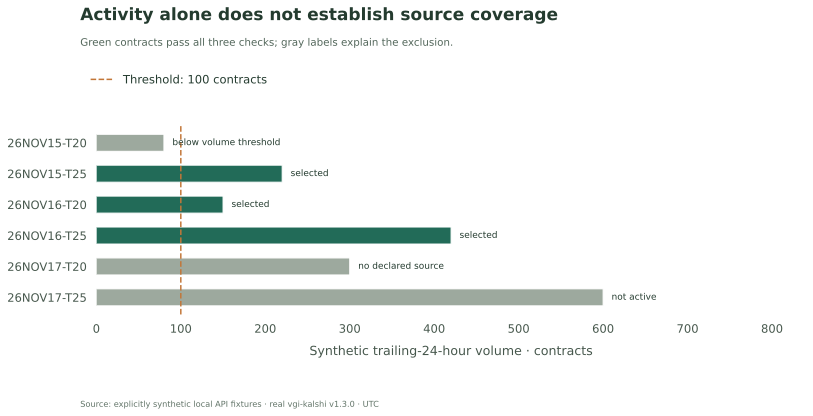

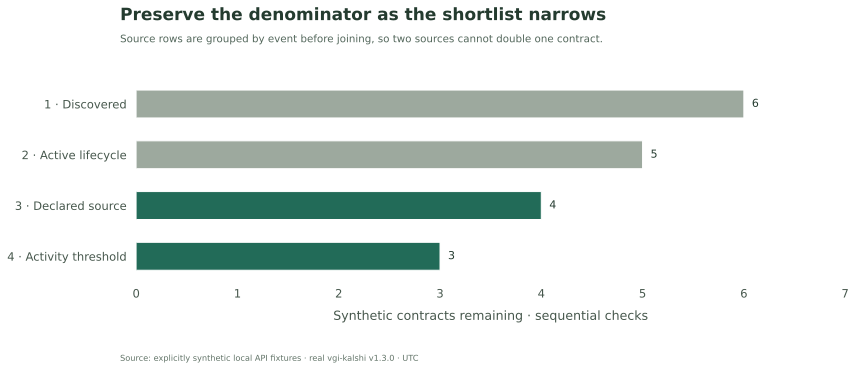

In [20]:
example.discovery_charts(screened, funnel, MIN_VOLUME_CONTRACTS)

In [21]:
example.describe_discovery(screened, venues, MIN_VOLUME_CONTRACTS)

At **100 contracts** of trailing-24-hour volume, **3 of 6 contracts** pass lifecycle, declared-source and activity checks. **2** belong to the event with no declared sources. A source URL is provenance metadata, not verification of its content. The exchange-wide flag is true while **1 venue** has trading paused; these rows do not map a market to a venue, so they cannot certify its tradability. The detailed event says its threshold markets are not mutually exclusive: their YES prices should not be added as a probability partition.

Verify the catalog lookup, event/detail agreement and join cardinality. The missing-source event remains visible with a zero count, and its high-volume contracts cannot enter the shortlist.

In [22]:
%%sql checks <<
SELECT 'series key resolved once' AS invariant, (SELECT count(*) FROM series_catalog WHERE ticker='DEMOWX')=1 AS passed
UNION ALL SELECT 'six source contracts', (SELECT count(*) FROM contracts)=6
UNION ALL SELECT 'three events agree with detail', (SELECT count(*) FROM event_list e JOIN event_detail d USING(event_ticker) WHERE e.title=d.title)=3
UNION ALL SELECT 'sources do not multiply contracts', (SELECT count(*)=count(DISTINCT ticker) AND count(*)=6 FROM screened)
UNION ALL SELECT 'source fanout remains explicit', (SELECT count(*) FROM source_rows)=4
UNION ALL SELECT 'no missing-source contract selected', NOT EXISTS(SELECT 1 FROM screened WHERE source_count=0 AND selected)
UNION ALL SELECT 'overlapping thresholds are not exclusive', (SELECT bool_and(NOT mutually_exclusive) FROM event_detail)
UNION ALL SELECT 'venue differs from overall flag', (SELECT count(*) FROM venue_status WHERE trading_active_overall AND NOT trading_active)=1;

In [23]:
example.check(checks)
example.audit(
    [
        "/series",
        "/exchange/status",
        "/markets",
        "/events",
        *[f"/events/DEMOWX-26NOV{d}" for d in (15, 16, 17)],
        *[f"/events/DEMOWX-26NOV{d}/metadata" for d in (15, 16, 17)],
    ]
)

,invariant,passed
0,series key resolved once,True
1,six source contracts,True
2,three events agree with detail,True
3,sources do not multiply contracts,True
4,source fanout remains explicit,True
5,no missing-source contract selected,True
6,overlapping thresholds are not exclusive,True
7,venue differs from overall flag,True


**Verified:** 10 local GET requests, no unexpected requests, and an empty SQL secret inventory. Every displayed source row came through the released worker.

**Experiment:** change only `MIN_VOLUME_CONTRACTS` from 100 to 300 and run all cells in a separate copy. Predict which active, sourced contracts remain. The fixture responses and six-contract denominator stay fixed; only the review policy changes. Try 1000 as a boundary: an empty shortlist is a valid result, not an empty source demonstration.

In [24]:
example.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-kalshi](https://github.com/Query-farm/vgi-kalshi)
